01. Import library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

02. Tarik Dataset

In [53]:
df = pd.read_csv("Dataset.csv")

03. Eksplorasi data

In [54]:
df.head()

,Waktu,Suhu (C),Kelembapan Tanah (ADC),LDR (ADC),Keterangan
0,10/13/2026 13:12,NaN,0,0,Cukup
1,10/13/2026 13:13,NaN,0,0,Cukup
2,10/13/2026 13:14,NaN,0,0,Cukup
3,10/13/2026 13:15,NaN,4095,15,Defisit Air Ringan
4,10/13/2026 13:16,NaN,4095,23,Defisit Air Ringan


In [ ]:
# Mengecek jumlah baris dan kolom pada Dataset
df.shape

(807, 5)

In [ ]:
# Mengecek infomasi data kolom, jumlah nilai bukan null dan tipe data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 807 entries, 0 to 806
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Waktu                   807 non-null    str    
 1   Suhu (C)                700 non-null    float64
 2   Kelembapan Tanah (ADC)  807 non-null    int64  
 3   LDR (ADC)               807 non-null    int64  
 4   Keterangan              807 non-null    str    
dtypes: float64(1), int64(2), str(2)
memory usage: 31.7 KB


In [57]:
df.describe()

,Suhu (C),Kelembapan Tanah (ADC),LDR (ADC)
count,700.000000,807.000000,807.000000
mean,30.776286,2583.857497,1955.749690
std,6.111897,1519.885433,1816.909893
min,24.100000,0.000000,0.000000
25%,26.700000,1240.000000,122.500000
50%,28.000000,2607.000000,2570.000000
75%,35.200000,4095.000000,4005.000000
max,55.000000,4095.000000,4095.000000


In [ ]:
# Mengecek missing value
df.isnull().sum()

Waktu                       0
Suhu (C)                  107
Kelembapan Tanah (ADC)      0
LDR (ADC)                   0
Keterangan                  0
dtype: int64

In [ ]:
# Melihat distribusi kelas
df["Keterangan"].value_counts()

Keterangan
Defisit Air Ringan    382
Cukup                 344
Defisit Air Sedang     65
Defisit Air Berat      16
Name: count, dtype: int64

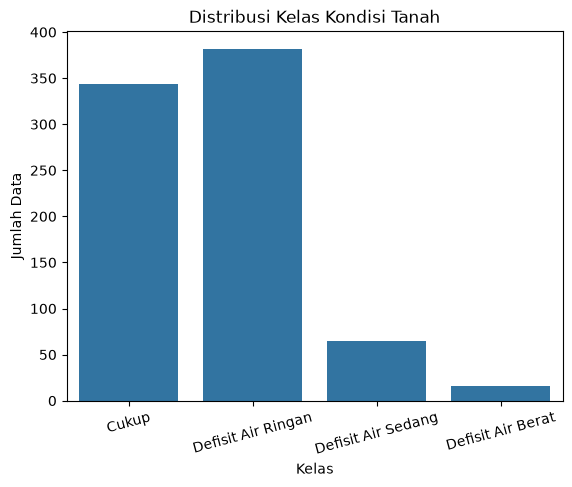

In [ ]:
# Visualisasi distribusi kelas
sns.countplot(x="Keterangan", data=df)
plt.xlabel("Kelas")
plt.ylabel("Jumlah Data")
plt.title("Distribusi Kelas Kondisi Tanah")
plt.xticks(rotation=15)
plt.show()

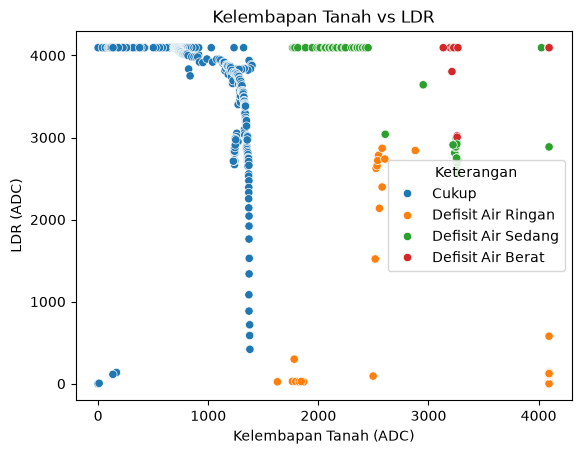

In [ ]:
# Visualisasi fitur 
sns.scatterplot(data=df, x="Kelembapan Tanah (ADC)", y="LDR (ADC)", hue="Keterangan")
plt.title("Kelembapan Tanah vs LDR")
plt.show()

04. Pre-Processing

In [ ]:
# Mengahapus kolom waktu
df = df.drop("Waktu", axis=1)

In [ ]:
# Mengisi nilai suhu yang hilang dengan median
imputer_median = SimpleImputer(strategy='median')
df['Suhu (C)'] = imputer_median.fit_transform(df[['Suhu (C)']])

In [ ]:
# Label encoding untuk target (Keterangan)
pemetaan = {
    "Cukup": 0,
    "Defisit Air Ringan": 1,
    "Defisit Air Sedang": 2,
    "Defisit Air Berat": 3
}
df["Keterangan_Encoded"] = df["Keterangan"].map(pemetaan)

In [ ]:
# Pendefinisian ulang label
nama_kelas = ["Cukup", "Defisit Air Ringan", "Defisit Air Sedang", "Defisit Air Berat"]

05. Menentukan X dan Y

In [ ]:
# Memisahkan fitur dan target
X = df.drop(["Keterangan","Keterangan_Encoded"], axis=1)
y = df["Keterangan_Encoded"]
print(X.shape)
print(y.shape)

(807, 3)
(807,)


06. Train-Test Split

In [ ]:
# Split data train & test
X_train, X_test, y_train, y_test = train_test_split(
 X,
 y,
 test_size=0.2,
 random_state=42,
 stratify=y
)

In [87]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (645, 3)
X_test : (162, 3)
y_train: (645,)
y_test : (162,)


07. Membangun model Decision Tree

In [ ]:
# Membuat model dasar
dt_model = DecisionTreeClassifier(criterion="gini", random_state=42)

In [ ]:
# Training dataset
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [ ]:
# Melakukan nilai prediksi
y_pred_dt = dt_model.predict(X_test)

In [ ]:
# Hasil prediksi
print(y_pred_dt)

[1 1 0 1 0 1 2 0 2 1 1 0 0 0 0 1 2 0 1 1 1 1 0 0 1 1 0 1 1 1 0 3 1 1 0 0 1
 0 0 1 0 2 0 0 1 0 1 0 1 0 0 1 1 1 0 1 0 1 0 1 1 0 0 0 1 0 1 1 1 1 0 1 0 1
 0 0 2 1 0 3 1 0 0 1 2 0 1 1 2 1 1 2 0 1 1 0 1 0 1 1 0 1 0 0 2 1 1 0 0 1 1
 1 0 1 1 0 1 2 0 2 1 0 0 1 1 2 1 1 0 1 0 0 1 1 0 0 1 0 0 1 1 1 1 0 2 1 1 0
 0 0 1 0 0 3 0 0 0 1 0 0 1 1]


In [ ]:
# Hasil data asli
print(y_test.values)

[1 1 0 1 0 1 2 0 2 1 1 0 0 0 0 1 2 0 1 1 1 1 0 0 1 1 0 1 1 1 0 3 1 1 0 0 1
 0 0 1 0 2 0 0 1 0 1 0 1 0 0 1 1 1 0 1 0 1 0 1 1 0 0 0 1 0 1 1 1 1 0 1 0 1
 0 0 2 1 0 3 1 0 0 1 2 0 1 1 2 1 1 2 0 1 1 0 1 0 1 1 0 1 0 0 2 1 1 0 0 1 1
 1 0 1 1 0 1 2 0 2 1 0 0 1 1 2 1 1 0 1 0 0 1 1 0 0 1 0 0 1 1 1 1 0 2 1 1 0
 0 0 1 0 0 3 0 0 0 1 0 0 1 1]


In [ ]:
# Pengukuran akurasi
accuracy_dt = accuracy_score(
 y_test,
 y_pred_dt
)
print("Accuracy:", accuracy_dt)

Accuracy: 1.0


In [ ]:
# Classification Report
print(classification_report(y_test, y_pred_dt, target_names=nama_kelas))

                    precision    recall  f1-score   support

             Cukup       1.00      1.00      1.00        69
Defisit Air Ringan       1.00      1.00      1.00        77
Defisit Air Sedang       1.00      1.00      1.00        13
 Defisit Air Berat       1.00      1.00      1.00         3

          accuracy                           1.00       162
         macro avg       1.00      1.00      1.00       162
      weighted avg       1.00      1.00      1.00       162



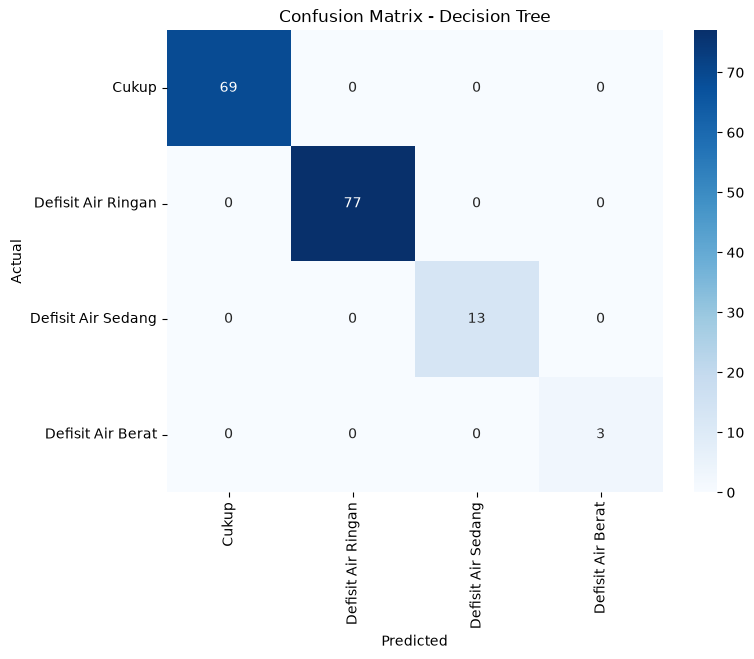

In [ ]:
# Confusion Matrix Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues",
            xticklabels=nama_kelas, yticklabels=nama_kelas)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

08. Visualisasi Decision Tree

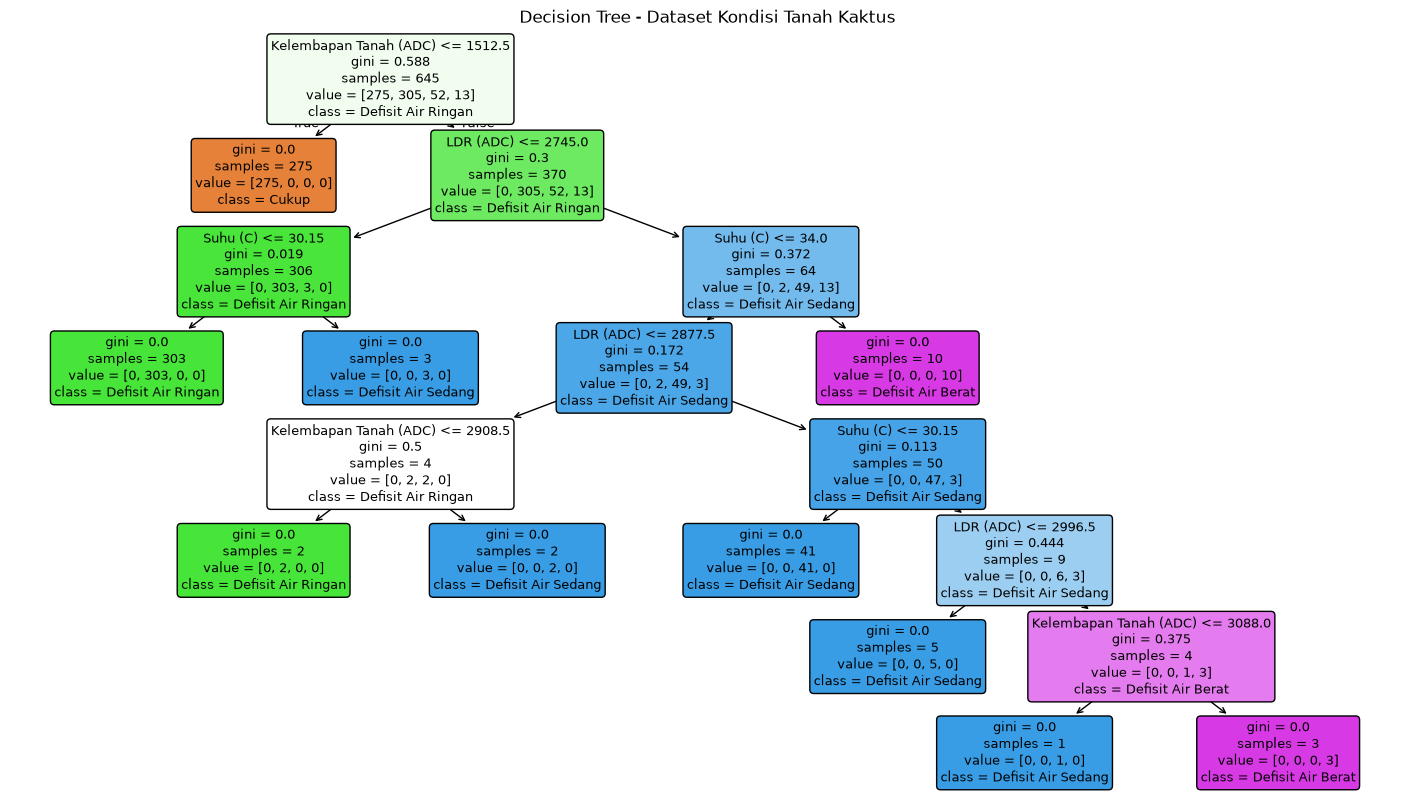

In [ ]:
# Visualisasi Decision tree
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 10))
plot_tree(dt_model, feature_names=X.columns, class_names=list(nama_kelas),
          filled=True, rounded=True)
plt.title("Decision Tree - Dataset Kondisi Tanah Kaktus")
plt.show()

09. Pengamatan Overfitting

In [ ]:
# Lihat kedalaman model
print("Depth:", dt_model.get_depth())

Depth: 7


In [ ]:
# Lihat Jumlah Leaf
print("Leaves:", dt_model.get_n_leaves())

Leaves: 10


In [ ]:
# Kemudian hitung accuracy training
train_pred_dt = dt_model.predict(X_train)
train_accuracy_dt = accuracy_score(
 y_train,
 train_pred_dt
)
print("Training Accuracy:", train_accuracy_dt)
print("Testing Accuracy :", accuracy_dt)

Training Accuracy: 1.0
Testing Accuracy : 1.0


10. Eksperimen max_depth

In [ ]:
# Buat beberapa model
depths = [1, 2, 3, 4, 5, 6, 8, 10]
results = []
for depth in depths:
 model = DecisionTreeClassifier(
 max_depth=depth,
 random_state=42
 )
 model.fit(X_train, y_train)
 train_pred = model.predict(X_train)
 test_pred = model.predict(X_test)
 train_acc = accuracy_score(
 y_train,
 train_pred
 )
 test_acc = accuracy_score(
 y_test,
 test_pred
 )
 results.append([
 depth,
 train_acc,
 test_acc
 ])

In [ ]:
# Lihat hasil model yang dibuat
depth_results = pd.DataFrame(
 results,
 columns=[
 "max_depth",
 "train_accuracy",
 "test_accuracy"
 ]
)
depth_results

,max_depth,train_accuracy,test_accuracy
0,1,0.899225,0.901235
1,2,0.972093,0.969136
2,3,0.992248,0.987654
3,4,0.992248,0.981481
4,5,0.995349,0.993827
5,6,0.998450,1.000000
6,8,1.000000,1.000000
7,10,1.000000,1.000000


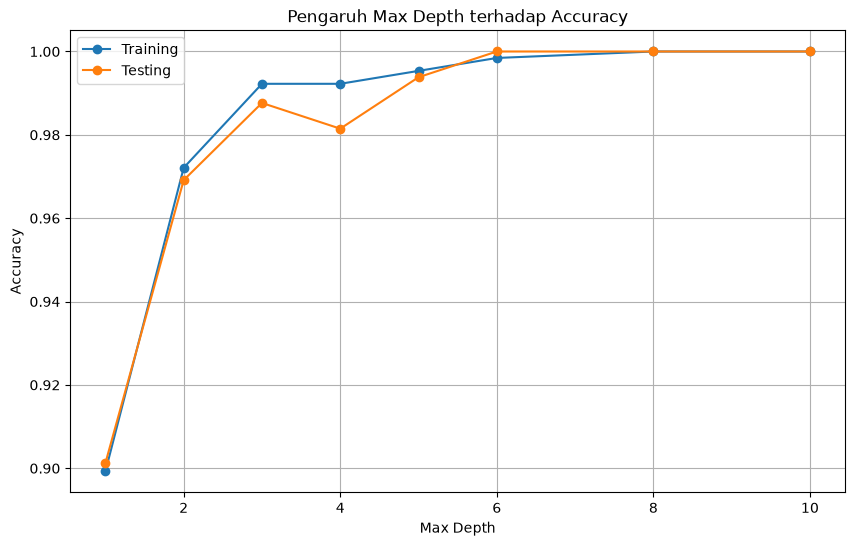

In [ ]:
# Visualisasi pwngaruh max_depth
plt.figure(figsize=(10, 6))
plt.plot(depth_results["max_depth"], depth_results["train_accuracy"], marker="o", label="Training")
plt.plot(depth_results["max_depth"], depth_results["test_accuracy"], marker="o", label="Testing")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Pengaruh Max Depth terhadap Accuracy")
plt.legend()
plt.grid()
plt.show()

11. Uji Coba data baru

In [ ]:
# Uji Coba data baru
data_baru = pd.DataFrame([[15.0, 1589, 4000]], columns=X.columns)

pred = dt_model.predict(data_baru)
print("Prediksi:", nama_kelas[pred[0]])
print(dt_model.predict_proba(data_baru))

Prediksi: Defisit Air Sedang
[[0. 0. 1. 0.]]
